# Détection de maladies foliaires avec YOLO11 : de l'entraînement au déploiement

**Projet IA Engineer / Computer Vision** : détection d'objets sur le dataset **PlantDoc** (images "in the wild", 29 classes de maladies et de feuilles saines), avec :

1. Préparation des données (conversion Pascal VOC → format YOLO, split train/val/test)
2. Analyse exploratoire (déséquilibre des classes, taille des boîtes)
3. Fine-tuning de **YOLO11s** (transfer learning)
4. Évaluation rigoureuse sur le jeu de test (mAP, par classe, matrice de confusion)
5. Benchmark de latence (PyTorch vs ONNX)
6. Export **ONNX**, API **FastAPI**, **Dockerfile**
7. Génération des lignes à mettre dans le CV

**Dataset** : [PlantDoc Object Detection Dataset](https://github.com/pratikkayal/PlantDoc-Object-Detection-Dataset) (GitHub, ~2 356 images d'entraînement, 237 de test, annotations Pascal VOC). Aucun compte ni clé API requis.

**Environnement** : Google Colab (GPU T4 gratuit) ou Kaggle Notebook. Durée totale : ~30 à 40 min.

> PlantDoc est un dataset **difficile** (fonds complexes, classes proches visuellement, déséquilibre). Un mAP50 modeste est normal ; la valeur du projet vient de l'analyse d'erreurs et du déploiement, pas d'un score parfait.

## 0. Installation et configuration

In [1]:
!pip install -q ultralytics fastapi "uvicorn[standard]" python-multipart httpx onnx onnxruntime pandas matplotlib

In [2]:
import os, re, random, shutil, time, json, sys
from pathlib import Path
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ---- Hyperparamètres (modifiables) ----
MODEL_WEIGHTS = "yolo11s.pt"   # yolo11n.pt (rapide) / yolo11s.pt / yolo11m.pt (plus précis)
EPOCHS = 60
IMGSZ = 640
BATCH = 16
RUN_ABLATION = False           # True pour comparer yolo11n / yolo11m (plus long)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("GPU disponible :", torch.cuda.is_available())
if not torch.cuda.is_available():
    print("⚠️ Active un GPU : Colab > Exécution > Modifier le type d'exécution > T4 GPU")
else:
    print(torch.cuda.get_device_name(0))

GPU disponible : True
Tesla T4


## 1. Téléchargement du dataset

Clone superficiel (`--depth 1`) du dépôt GitHub (~2 Go, compter 1 à 3 minutes).

In [3]:
if not Path("PlantDoc-Object-Detection-Dataset").exists():
    !git clone --depth 1 https://github.com/pratikkayal/PlantDoc-Object-Detection-Dataset.git
SRC = Path("PlantDoc-Object-Detection-Dataset")
print(os.listdir(SRC))
print("TRAIN :", len(os.listdir(SRC/"TRAIN")), "fichiers | TEST :", len(os.listdir(SRC/"TEST")), "fichiers")

Cloning into 'PlantDoc-Object-Detection-Dataset'...
remote: Enumerating objects: 5189, done.
remote: Counting objects: 100% (5189/5189), done.
remote: Compressing objects: 100% (2752/2752), done.
remote: Total 5189 (delta 2440), reused 5173 (delta 2437), pack-reused 0 (from 0)
Receiving objects: 100% (5189/5189), 941.87 MiB | 18.42 MiB/s, done.
Resolving deltas: 100% (2440/2440), done.
Updating files: 100% (5200/5200), done.
['README.md', 'LICENSE.txt', 'TRAIN', 'TEST', 'train_labels.csv', 'test_labels.csv', '.git']
TRAIN : 4720 fichiers | TEST : 476 fichiers


## 2. Conversion Pascal VOC → format YOLO

Points d'attention (le dataset est "sale") :
- certains noms de fichiers contiennent des `?`, `%` ou des extensions étranges → on **renomme** proprement les images ;
- certaines paires image/XML sont manquantes ou corrompues → elles sont **ignorées** ;
- on utilise la **taille réelle** de l'image (pas celle écrite dans le XML, parfois fausse) et on **clippe** les boîtes aux bords de l'image.

Split : `TRAIN` → 90 % train / 10 % validation ; `TEST` officiel conservé **intact** pour l'évaluation finale.

In [4]:
OUT = Path("plantdoc_yolo")
if OUT.exists():
    shutil.rmtree(OUT)

def collect_pairs(split_dir):
    """Associe chaque XML à son image (gère les noms de fichiers atypiques)."""
    folder = SRC / split_dir
    files = os.listdir(folder)
    imgs = {f.lower(): f for f in files if not f.lower().endswith(".xml")}
    pairs = []
    for f in sorted(files):
        if not f.endswith(".xml"):
            continue
        stem = f[:-4]
        for cand in (stem, stem + ".jpg", stem + ".jpeg", stem + ".png"):
            if cand.lower() in imgs:
                pairs.append((folder / imgs[cand.lower()], folder / f))
                break
    return pairs

train_pairs_all = collect_pairs("TRAIN")
test_pairs = collect_pairs("TEST")
print("Paires image/XML  train :", len(train_pairs_all), "| test :", len(test_pairs))

# Liste des classes (nettoyage des espaces)
class_names = set()
for _, x in train_pairs_all + test_pairs:
    for o in ET.parse(x).findall("object"):
        class_names.add(o.find("name").text.strip())
class_names = sorted(class_names)
class2id = {c: i for i, c in enumerate(class_names)}
print(len(class_names), "classes")

Paires image/XML  train : 2354 | test : 237
29 classes


In [5]:
def convert(pairs, split):
    (OUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUT / "labels" / split).mkdir(parents=True, exist_ok=True)
    kept, skipped = 0, 0
    for i, (img_path, xml_path) in enumerate(pairs):
        try:
            img = Image.open(img_path).convert("RGB")
            W, H = img.size
            lines = []
            for o in ET.parse(xml_path).findall("object"):
                name = o.find("name").text.strip()
                bb = o.find("bndbox")
                x1, y1, x2, y2 = [float(bb.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax")]
                x1, x2 = max(0, min(x1, W)), max(0, min(x2, W))
                y1, y2 = max(0, min(y1, H)), max(0, min(y2, H))
                if (x2 - x1) < 2 or (y2 - y1) < 2:
                    continue
                cx, cy = (x1 + x2) / 2 / W, (y1 + y2) / 2 / H
                w, h = (x2 - x1) / W, (y2 - y1) / H
                lines.append(f"{class2id[name]} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")
            if not lines:
                skipped += 1
                continue
            stem = f"{split}_{i:05d}"
            img.save(OUT / "images" / split / f"{stem}.jpg", quality=95)
            (OUT / "labels" / split / f"{stem}.txt").write_text("\n".join(lines))
            kept += 1
        except Exception as e:
            skipped += 1
    print(f"{split:5s} : {kept} images conservées, {skipped} ignorées")

random.shuffle(train_pairs_all)
n_val = int(0.10 * len(train_pairs_all))
val_pairs, train_pairs = train_pairs_all[:n_val], train_pairs_all[n_val:]

convert(train_pairs, "train")
convert(val_pairs, "val")
convert(test_pairs, "test")

yaml_text = f"path: {OUT.resolve()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
for i, c in enumerate(class_names):
    yaml_text += f"  {i}: {c}\n"
(OUT / "data.yaml").write_text(yaml_text)
print(yaml_text[:300], "...")

train : 2109 images conservées, 10 ignorées
val   : 235 images conservées, 0 ignorées
test  : 236 images conservées, 1 ignorées
path: /content/plantdoc_yolo
train: images/train
val: images/val
test: images/test
names:
  0: Apple Scab Leaf
  1: Apple leaf
  2: Apple rust leaf
  3: Bell_pepper leaf
  4: Bell_pepper leaf spot
  5: Blueberry leaf
  6: Cherry leaf
  7: Corn Gray leaf spot
  8: Corn leaf blight
  9: Corn rust leaf ...


## 3. Analyse exploratoire (EDA)

       images  boites
split                
test      236     452
train    2109    7571
val       235     884


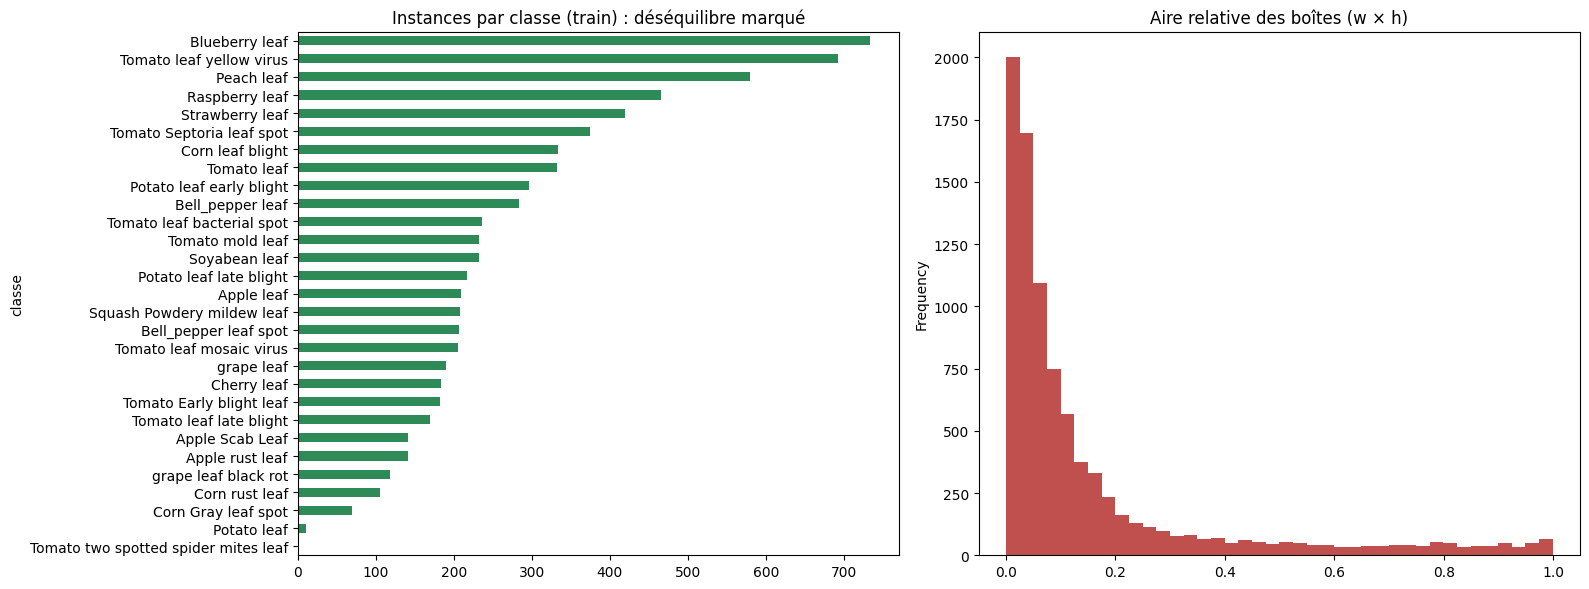

Ratio max/min d'instances : 734 / 1 = 734x
Boîtes par image (moyenne) : 3.45


In [6]:
def load_labels(split):
    rows = []
    for f in (OUT / "labels" / split).glob("*.txt"):
        for line in f.read_text().splitlines():
            c, cx, cy, w, h = line.split()
            rows.append((split, f.stem, int(c), float(cx), float(cy), float(w), float(h)))
    return pd.DataFrame(rows, columns=["split", "img", "cls", "cx", "cy", "w", "h"])

df = pd.concat([load_labels(s) for s in ("train", "val", "test")])
df["classe"] = df["cls"].map(lambda i: class_names[i])

print(df.groupby("split").agg(images=("img", "nunique"), boites=("cls", "size")))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
counts = df[df.split == "train"]["classe"].value_counts()
counts.sort_values().plot.barh(ax=ax[0], color="#2e8b57")
ax[0].set_title("Instances par classe (train) : déséquilibre marqué")
(df["w"] * df["h"]).plot.hist(bins=40, ax=ax[1], color="#c0504d")
ax[1].set_title("Aire relative des boîtes (w × h)")
plt.tight_layout(); plt.show()

print(f"Ratio max/min d'instances : {counts.max()} / {counts.min()} = {counts.max()/counts.min():.0f}x")
print("Boîtes par image (moyenne) :", round(df.groupby("img").size().mean(), 2))

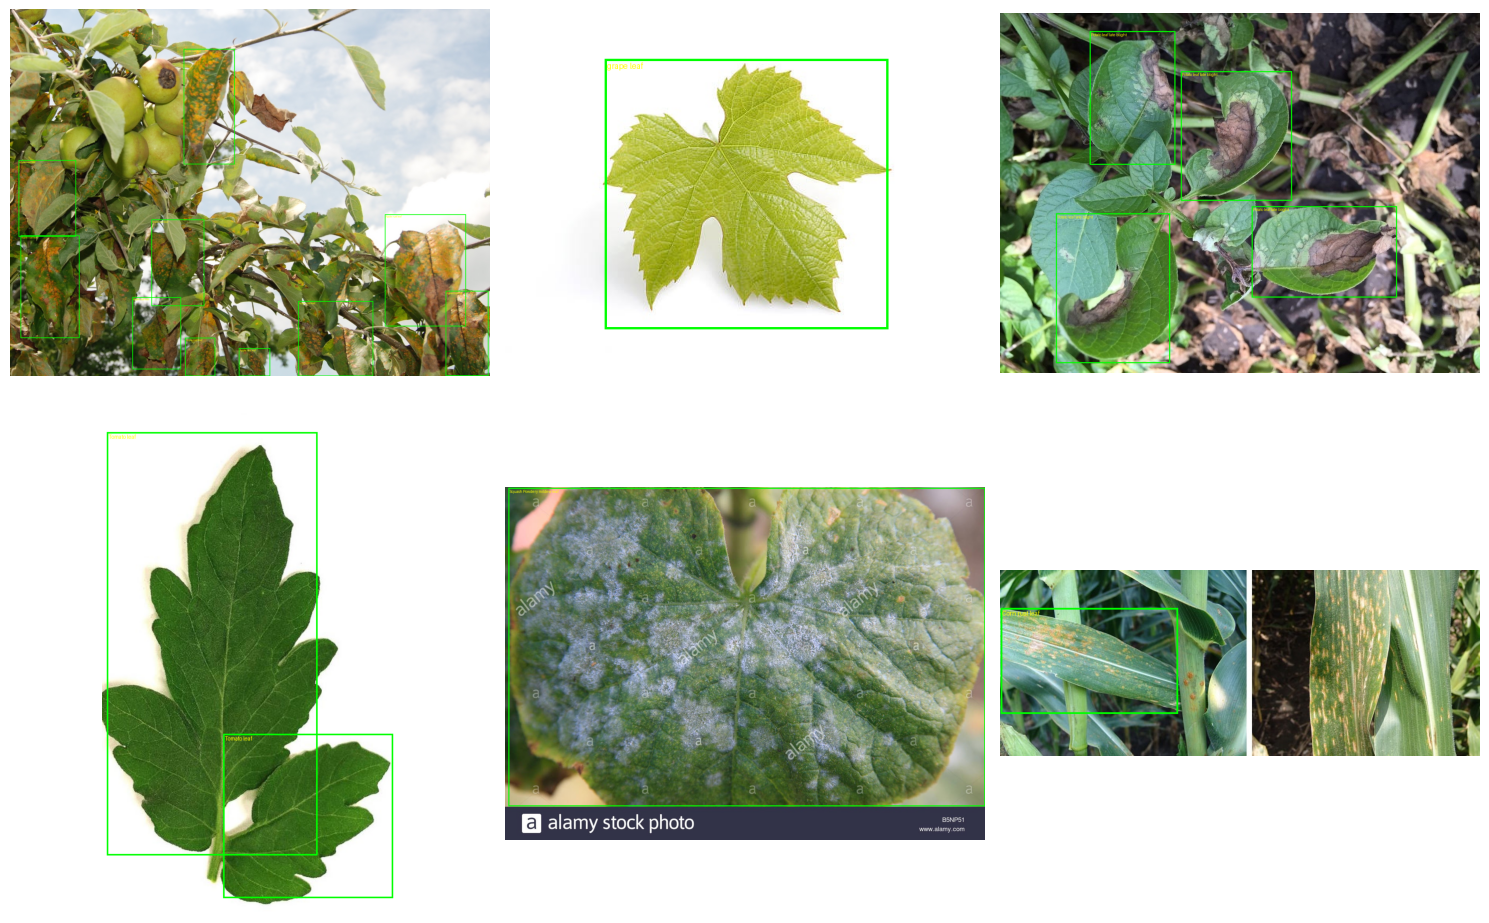

In [7]:
def draw_gt(split, n=6):
    imgs = random.sample(list((OUT / "images" / split).glob("*.jpg")), n)
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    for ax, p in zip(axes.ravel(), imgs):
        im = Image.open(p); W, H = im.size
        d = ImageDraw.Draw(im)
        for line in (OUT / "labels" / split / f"{p.stem}.txt").read_text().splitlines():
            c, cx, cy, w, h = line.split(); c = int(c)
            cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
            d.rectangle([cx - w/2, cy - h/2, cx + w/2, cy + h/2], outline="lime", width=3)
            d.text((cx - w/2 + 3, cy - h/2 + 3), class_names[c], fill="yellow")
        ax.imshow(im); ax.axis("off")
    plt.tight_layout(); plt.show()

draw_gt("train")

## 4. Entraînement (fine-tuning YOLO11)

On part de poids pré-entraînés sur COCO (**transfer learning**). Choix :
- `patience=15` : arrêt anticipé si pas d'amélioration sur la validation ;
- `cos_lr=True` : décroissance cosinus du learning rate ;
- `close_mosaic=10` : désactive la mosaïque sur les 10 dernières époques (stabilise la convergence) ;
- augmentations par défaut d'Ultralytics (mosaïque, HSV, flip, scale).

In [8]:
from ultralytics import YOLO

model = YOLO(MODEL_WEIGHTS)
results = model.train(
    data=str(OUT / "data.yaml"),
    epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
    patience=15, seed=SEED, cos_lr=True, close_mosaic=10,
    project="runs", name=f"plantdoc_{Path(MODEL_WEIGHTS).stem}",
    device=DEVICE, workers=2, plots=True,
)
RUN_DIR = Path(results.save_dir)
BEST = RUN_DIR / "weights" / "best.pt"
print("Meilleurs poids :", BEST)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=plantdoc_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=

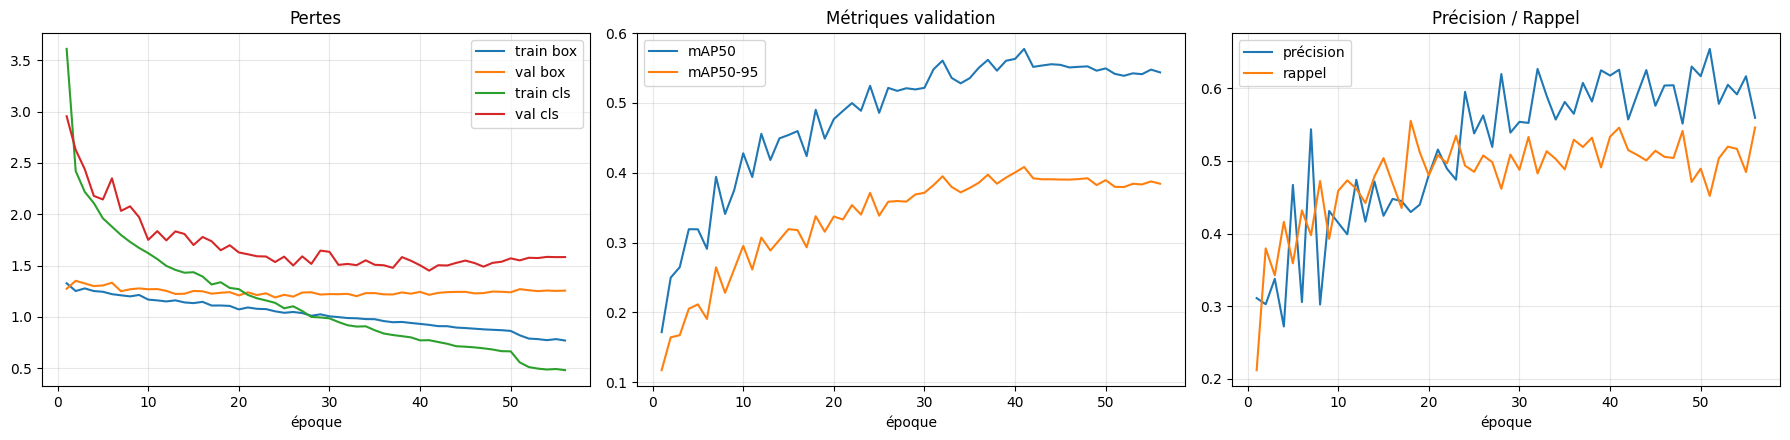

In [9]:
res = pd.read_csv(RUN_DIR / "results.csv")
res.columns = [c.strip() for c in res.columns]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(res["epoch"], res["train/box_loss"], label="train box"); ax[0].plot(res["epoch"], res["val/box_loss"], label="val box")
ax[0].plot(res["epoch"], res["train/cls_loss"], label="train cls"); ax[0].plot(res["epoch"], res["val/cls_loss"], label="val cls")
ax[0].set_title("Pertes"); ax[0].legend()
ax[1].plot(res["epoch"], res["metrics/mAP50(B)"], label="mAP50"); ax[1].plot(res["epoch"], res["metrics/mAP50-95(B)"], label="mAP50-95")
ax[1].set_title("Métriques validation"); ax[1].legend()
ax[2].plot(res["epoch"], res["metrics/precision(B)"], label="précision"); ax[2].plot(res["epoch"], res["metrics/recall(B)"], label="rappel")
ax[2].set_title("Précision / Rappel"); ax[2].legend()
for a in ax: a.set_xlabel("époque"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Évaluation finale sur le jeu de TEST

Le jeu de test n'a **jamais** été utilisé pendant l'entraînement ni pour le choix du meilleur checkpoint (qui repose sur la validation).

In [10]:
best_model = YOLO(str(BEST))
m = best_model.val(data=str(OUT / "data.yaml"), split="test", imgsz=IMGSZ, batch=BATCH,
                   plots=True, project="runs", name="test_eval", device=DEVICE)

test_results = {
    "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map),
    "precision": float(m.box.mp), "recall": float(m.box.mr),
}
print(json.dumps({k: round(v, 4) for k, v in test_results.items()}, indent=2))

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,424,023 parameters, 0 gradients, 21.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 26.9±18.6 MB/s, size: 277.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/plantdoc_yolo/labels/test... 236 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 236/236 418.7it/s 0.6s
val: New cache created: /content/plantdoc_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 3.1it/s 4.9s
                   all        236        452      0.616      0.652      0.669      0.532
       Apple Scab Leaf         10         13      0.695      0.769       0.74      0.586
            Apple leaf          9         10      0.452        0.7      0.728      0.578
     

In [11]:
# Résultats par classe
n_test = df[df.split == "test"]["cls"].value_counts()
rows = []
for i, ci in enumerate(m.box.ap_class_index):
    rows.append({"classe": m.names[int(ci)], "instances_test": int(n_test.get(int(ci), 0)),
                 "AP50": round(float(m.box.ap50[i]), 3), "AP50-95": round(float(m.box.ap[i]), 3)})
per_class = pd.DataFrame(rows).sort_values("AP50", ascending=False).reset_index(drop=True)
display(per_class)

print("\n5 meilleures classes :", per_class.head(5)["classe"].tolist())
print("5 pires classes      :", per_class.tail(5)["classe"].tolist())

,classe,instances_test,AP50,AP50-95
0,Corn rust leaf,10,0.995,0.854
1,Strawberry leaf,30,0.984,0.847
2,grape leaf black rot,8,0.982,0.855
3,grape leaf,15,0.912,0.786
4,Raspberry leaf,17,0.890,0.814
5,Squash Powdery mildew leaf,6,0.847,0.781
6,Peach leaf,10,0.839,0.591
7,Bell_pepper leaf,11,0.823,0.698
8,Tomato leaf late blight,14,0.821,0.589
9,Apple rust leaf,11,0.815,0.682



5 meilleures classes : ['Corn rust leaf', 'Strawberry leaf', 'grape leaf black rot', 'grape leaf', 'Raspberry leaf']
5 pires classes      : ['Tomato leaf', 'Corn Gray leaf spot', 'Potato leaf early blight', 'Potato leaf late blight', 'Tomato leaf bacterial spot']


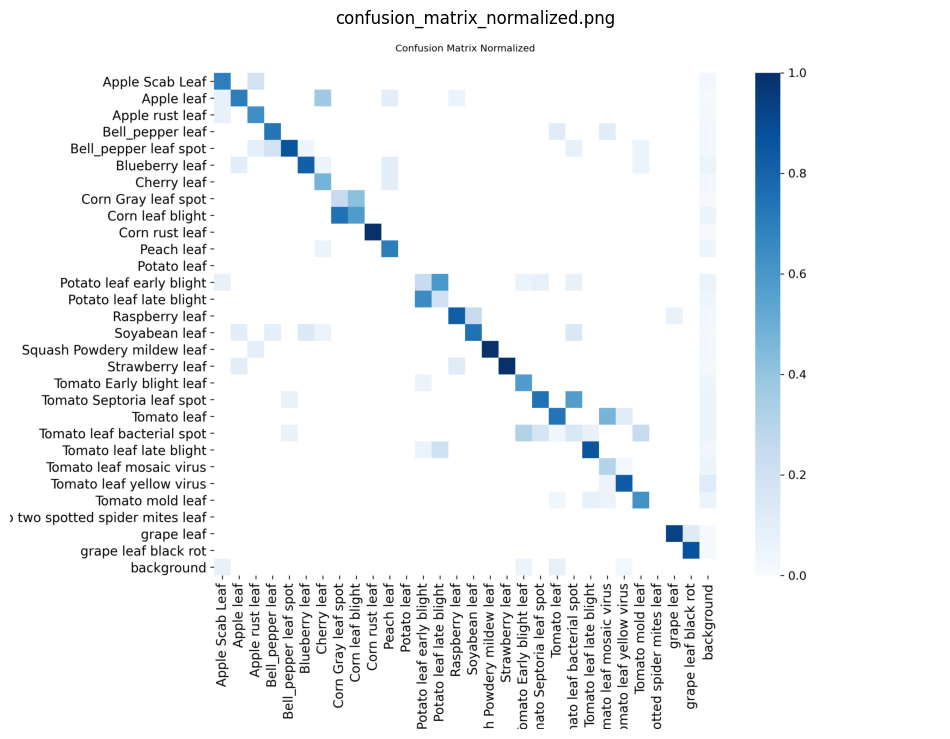

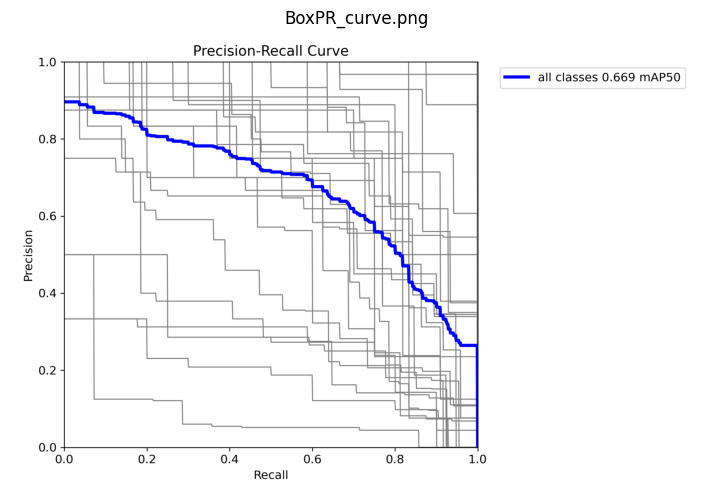

In [12]:
# Matrice de confusion et courbe PR générées par Ultralytics
EVAL_DIR = Path(m.save_dir)
for name in ("confusion_matrix_normalized.png", "BoxPR_curve.png"):
    p = EVAL_DIR / name
    if p.exists():
        plt.figure(figsize=(12, 10) if "confusion" in name else (9, 6))
        plt.imshow(Image.open(p)); plt.axis("off"); plt.title(name); plt.show()

### Analyse d'erreurs (à rédiger dans le README, c'est ce qui impressionne en entretien)

Regarde la matrice de confusion et la table par classe, puis réponds :
- Quelles classes sont confondues entre elles (ex. différentes maladies de la tomate, aspect visuel proche) ?
- Les classes rares (peu d'instances) ont-elles un AP plus faible ? Le déséquilibre explique-t-il les erreurs ?
- Les fausses détections viennent-elles du fond (feuillage, mains, sol) ?

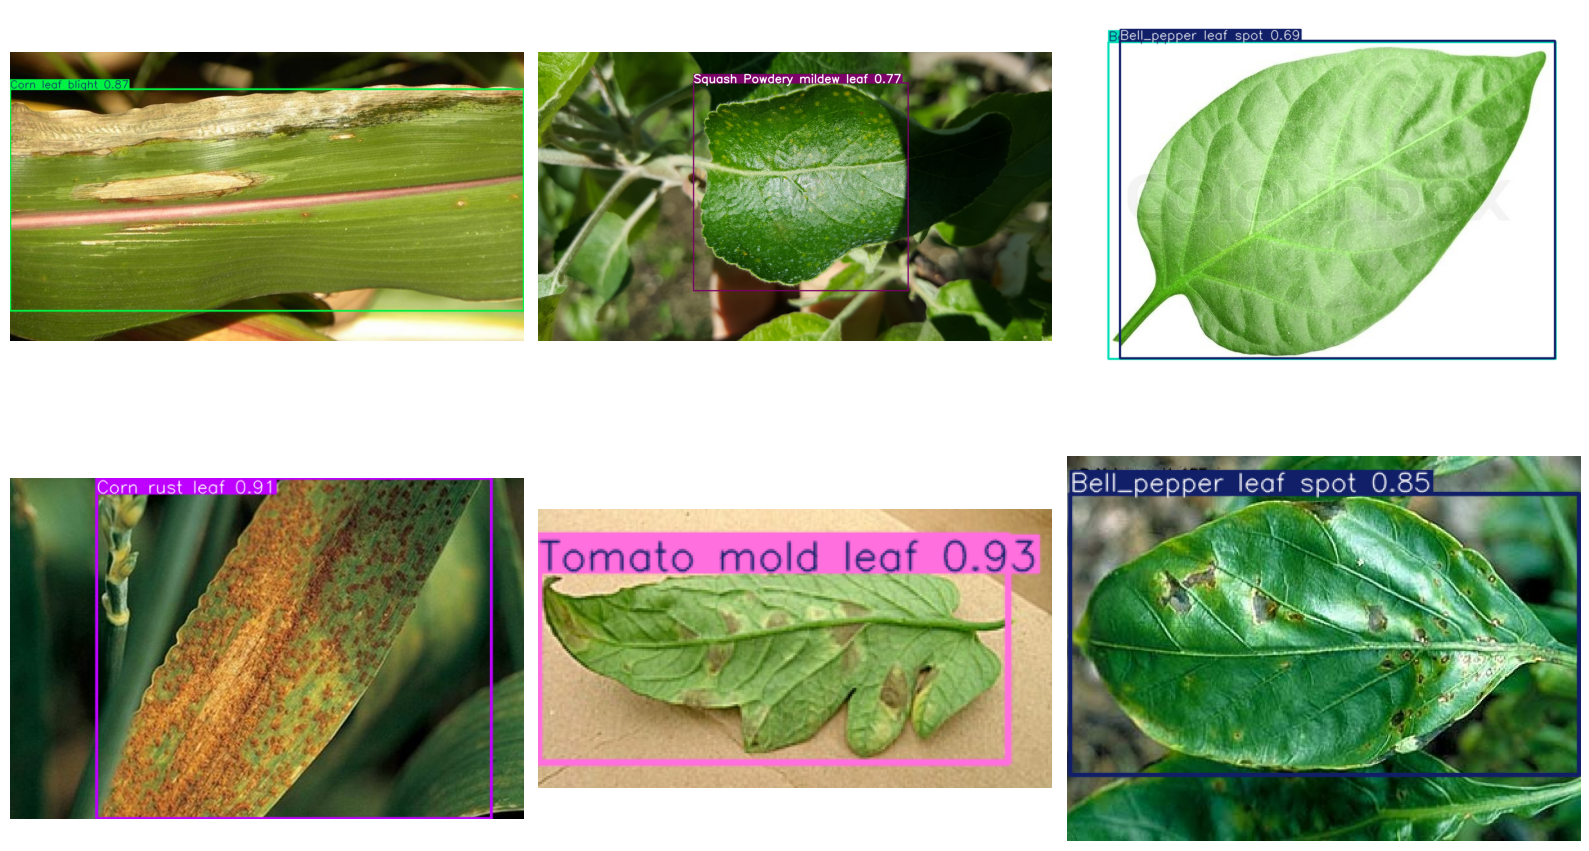

In [13]:
# Prédictions qualitatives sur des images de test
test_imgs = sorted((OUT / "images" / "test").glob("*.jpg"))
sample = random.sample(test_imgs, 6)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, p in zip(axes.ravel(), sample):
    r = best_model.predict(str(p), conf=0.25, imgsz=IMGSZ, verbose=False)[0]
    ax.imshow(r.plot()[..., ::-1]); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Benchmark de latence et export ONNX

Un projet "AI Engineer" se juge aussi sur la **vitesse d'inférence** : on compare PyTorch et ONNX Runtime.

In [14]:
def bench(mdl, paths, n=50, **kw):
    for p in paths[:5]:
        mdl.predict(str(p), verbose=False, imgsz=IMGSZ, **kw)          # warm-up
    t = []
    for p in paths[:n]:
        r = mdl.predict(str(p), verbose=False, imgsz=IMGSZ, **kw)[0]
        t.append(sum(r.speed.values()))                                  # pré + inférence + post (ms)
    return float(np.mean(t)), float(np.percentile(t, 95))

onnx_path = best_model.export(format="onnx", imgsz=IMGSZ, simplify=True, dynamic=False)
print("ONNX :", onnx_path, f"({Path(onnx_path).stat().st_size/1e6:.1f} Mo)")

onnx_model = YOLO(onnx_path, task="detect")
lat_pt = bench(best_model, test_imgs)
lat_onnx = bench(onnx_model, test_imgs)
latency = pd.DataFrame({"modèle": ["PyTorch (.pt)", "ONNX Runtime"],
                        "latence moyenne (ms)": [round(lat_pt[0], 1), round(lat_onnx[0], 1)],
                        "p95 (ms)": [round(lat_pt[1], 1), round(lat_onnx[1], 1)]})
latency["FPS"] = (1000 / latency["latence moyenne (ms)"]).round(1)
display(latency)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,424,023 parameters, 0 gradients, 21.5 GFLOPs

PyTorch: starting from '/content/runs/detect/runs/plantdoc_yolo11s/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 33, 8400) (18.3 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 222ms
Prepared 2 packages in 31ms
Installed 2 packages in 7ms
 + colorama==0.4.6
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 3.0s, saved as '/

,modèle,latence moyenne (ms),p95 (ms),FPS
0,PyTorch (.pt),15.8,25.6,63.3
1,ONNX Runtime,269.8,352.3,3.7


In [15]:
# Contrôle de cohérence : ONNX doit donner un mAP proche du modèle PyTorch
m_onnx = onnx_model.val(data=str(OUT / "data.yaml"), split="test", imgsz=IMGSZ, batch=1, plots=False,
                        project="runs", name="test_eval_onnx")
print(f"mAP50  PyTorch : {m.box.map50:.4f} | ONNX : {m_onnx.box.map50:.4f}")

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Loading /content/runs/detect/runs/plantdoc_yolo11s/weights/best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.32.0 with CPUExecutionProvider
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1359.1±427.9 MB/s, size: 78.9 KB)
val: Scanning /content/plantdoc_yolo/labels/test.cache... 236 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 236/236 82.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 236/236 3.5it/s 1:08
                   all        236        452       0.63      0.621      0.665      0.527
       Apple Scab Leaf         10         13      0.689      0.769       0.73      0.588
            Apple leaf          9         10      0.597        0.7      0.716       0.55
       Apple rust le

## 7. (Optionnel) Ablation : taille du modèle

Met `RUN_ABLATION = True` dans la cellule de configuration pour comparer `yolo11n` / `yolo11m` à `yolo11s`. Cela fournit un tableau de comparaison précision vs vitesse, très apprécié dans un rapport.

In [16]:
if RUN_ABLATION:
    abl = []
    for w in ["yolo11n.pt", "yolo11m.pt"]:
        mdl = YOLO(w)
        r = mdl.train(data=str(OUT / "data.yaml"), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=15,
                      seed=SEED, cos_lr=True, project="runs", name=f"plantdoc_{Path(w).stem}",
                      device=DEVICE, workers=2, plots=False)
        mm = YOLO(str(Path(r.save_dir) / "weights" / "best.pt"))
        mt = mm.val(data=str(OUT / "data.yaml"), split="test", imgsz=IMGSZ, plots=False, device=DEVICE,
                    project="runs", name=f"abl_{Path(w).stem}")
        lat = bench(mm, test_imgs)
        abl.append({"modèle": w, "mAP50": round(mt.box.map50, 3), "mAP50-95": round(mt.box.map, 3),
                    "latence (ms)": round(lat[0], 1)})
    abl.append({"modèle": MODEL_WEIGHTS, "mAP50": round(test_results["mAP50"], 3),
                "mAP50-95": round(test_results["mAP50-95"], 3), "latence (ms)": round(lat_pt[0], 1)})
    display(pd.DataFrame(abl))
else:
    print("Ablation désactivée (RUN_ABLATION=False).")

Ablation désactivée (RUN_ABLATION=False).


## 8. Déploiement : API FastAPI + Docker

On crée un dossier `deploy/` contenant tout ce qu'il faut pour servir le modèle (ONNX, CPU).

In [17]:
os.makedirs("deploy", exist_ok=True)
shutil.copy(onnx_path, "deploy/best.onnx")
shutil.copy(BEST, "deploy/best.pt")
print(os.listdir("deploy"))

['best.onnx', 'best.pt']


In [25]:
%%writefile deploy/app.py
import io
import os

from fastapi import FastAPI, File, HTTPException, Query, UploadFile
from fastapi.responses import Response
from PIL import Image
from ultralytics import YOLO

MODEL_PATH = os.getenv("MODEL_PATH", "best.onnx")
model = YOLO(MODEL_PATH, task="detect")

app = FastAPI(title="PlantDoc YOLO11 API", version="1.0.0",
              description="Détection de maladies foliaires (PlantDoc)")


def read_image(data: bytes) -> Image.Image:
    try:
        return Image.open(io.BytesIO(data)).convert("RGB")
    except Exception:
        raise HTTPException(status_code=400, detail="Fichier image invalide")


@app.get("/health")
def health():
    return {"status": "ok", "n_classes": len(model.names)}


@app.post("/predict")
async def predict(file: UploadFile = File(...), conf: float = Query(0.25, ge=0.0, le=1.0)):
    img = read_image(await file.read())
    r = model.predict(img, conf=conf, imgsz=640, verbose=False,agnostic_nms=True)[0]
    detections = [
        {
            "class": model.names[int(b.cls)],
            "confidence": round(float(b.conf), 4),
            "bbox_xyxy": [round(float(v), 1) for v in b.xyxy[0].tolist()],
        }
        for b in r.boxes
    ]
    return {"n_detections": len(detections), "inference_ms": round(r.speed["inference"], 1),
            "detections": detections}


@app.post("/predict/image")
async def predict_image(file: UploadFile = File(...), conf: float = Query(0.25, ge=0.0, le=1.0)):
    img = read_image(await file.read())
    r = model.predict(img, conf=conf, imgsz=640, verbose=False,agnostic_nms=True)[0]
    annotated = r.plot()[..., ::-1]          # BGR -> RGB
    buf = io.BytesIO()
    Image.fromarray(annotated).save(buf, format="JPEG", quality=90)
    return Response(content=buf.getvalue(), media_type="image/jpeg")

Overwriting deploy/app.py


In [19]:
%%writefile deploy/requirements.txt
ultralytics
onnxruntime
fastapi
uvicorn[standard]
python-multipart
pillow

Writing deploy/requirements.txt


In [20]:
%%writefile deploy/Dockerfile
FROM python:3.11-slim

RUN apt-get update && apt-get install -y --no-install-recommends libgl1 libglib2.0-0 \
    && rm -rf /var/lib/apt/lists/*

WORKDIR /app
RUN pip install --no-cache-dir torch torchvision --index-url https://download.pytorch.org/whl/cpu
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY app.py best.onnx ./
ENV MODEL_PATH=/app/best.onnx
EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]

Writing deploy/Dockerfile


Loading /content/deploy/best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.32.0 with CPUExecutionProvider
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...
{'status': 'ok', 'n_classes': 29}
Loading /content/deploy/best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.32.0 with CPUExecutionProvider
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...
{
  "n_detections": 2,
  "inference_ms": 292.5,
  "detections": [
    {
      "class": "Apple Scab Leaf",
      "confidence": 0.5331,
      "bbox_xyxy": [
        58.7,
        190.2,
        405.5,
        391.7
      ]
    },
    {
      "class": "Tomato leaf bacterial spot",
      "confidence": 0.4139,
      "bbox_xyxy": [
        58.8,
        188.3,
        407.8,
        392.1
      ]
    }
  ]
}


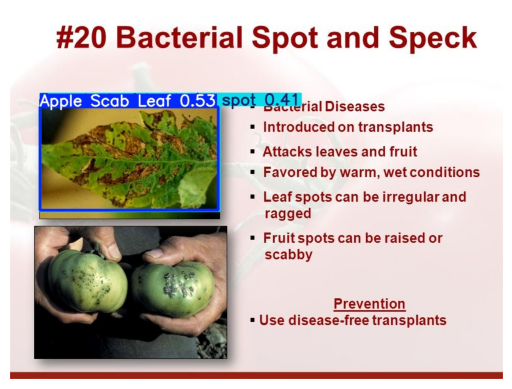

In [21]:
# Test de l'API dans le notebook (sans serveur) avec le TestClient de FastAPI
os.environ["MODEL_PATH"] = str(Path("deploy/best.onnx").resolve())
sys.path.insert(0, "deploy")
from fastapi.testclient import TestClient
import importlib, app as api_module
importlib.reload(api_module)
client = TestClient(api_module.app)

print(client.get("/health").json())
test_img = str(test_imgs[0])
with open(test_img, "rb") as f:
    resp = client.post("/predict?conf=0.25", files={"file": ("leaf.jpg", f, "image/jpeg")})
print(json.dumps(resp.json(), indent=2)[:800])

with open(test_img, "rb") as f:
    resp_img = client.post("/predict/image", files={"file": ("leaf.jpg", f, "image/jpeg")})
plt.imshow(Image.open(__import__("io").BytesIO(resp_img.content))); plt.axis("off"); plt.show()

### Lancer en local avec Docker (sur ta machine, pas dans Colab)

Télécharge le dossier `deploy/` (voir cellule suivante), puis :

```bash
cd deploy
docker build -t plantdoc-yolo-api .
docker run -p 8000:8000 plantdoc-yolo-api
# Documentation interactive : http://localhost:8000/docs
curl -X POST "http://localhost:8000/predict?conf=0.3" -F "file=@feuille.jpg"
```

Pour un déploiement public gratuit : **Hugging Face Spaces** (type Docker) ou **Render / Railway** avec ce même Dockerfile.

In [26]:
shutil.make_archive("deploy_plantdoc", "zip", "deploy")
shutil.make_archive("training_run", "zip", str(RUN_DIR))
try:
    from google.colab import files
    files.download("deploy_plantdoc.zip")
except Exception:
    print("Fichiers créés : deploy_plantdoc.zip, training_run.zip (télécharge-les depuis le panneau de fichiers)")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>